# Wellness Tourism Package Prediction: an MLOps pipeline for "Visit with Us"

**Business problem.** "Visit with Us" is launching a Wellness Tourism Package. Picking the
right customers to call by hand is slow and inconsistent, so campaigns miss buyers and waste
sales time.

**Objective.** Build an automated, repeatable pipeline that predicts whether a customer will
buy the package, and serve the prediction in a web app. The pipeline lives in GitHub and covers
data registration, cleaning, splitting, model tuning with experiment tracking, model commit,
and app deployment, all driven by GitHub Actions.

**How this notebook is organised**

| # | Section | Rubric area |
|---|---|---|
| 1 | Project structure and data registration | Data registration |
| 2 | Data understanding (EDA) | Supports data preparation |
| 3 | Data preparation | Data preparation |
| 4 | Model building and experiment tracking | Model building |
| 5 | Model deployment (Streamlit) | Model deployment |
| 6 | MLOps pipeline (GitHub Actions) | MLOps pipeline |
| 7 | Output evaluation: links and screenshots | Output evaluation |
| 8 | Insights and recommendations | |

Every code cell below was executed top to bottom, and each stage runs the same scripts the
GitHub Actions pipeline runs (`src/validate_data.py`, `src/prepare_data.py`, `src/train_model.py`).

In [1]:
GITHUB_URL = "https://github.com/phaniapsr/tourism-package-prediction"   # public GitHub repository
STREAMLIT_URL = ""   # deployed Streamlit Community Cloud app

import json, logging, os, subprocess, sys, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
logging.getLogger("streamlit").setLevel(logging.ERROR)
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

REPO = Path.cwd().parent                      # notebook/ sits one level below the repo root
sys.path.insert(0, str(REPO / "src"))
from common import (CATEGORICAL_FEATURES, FEATURES, METRICS_PATH, MLFLOW_DIR, MODEL_PATH,
                    NUMERIC_FEATURES, PROCESSED_DIR, RAW_DATA, TARGET)

# Chart style: one blue for the subject, orange only for a second series, gray for context.
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b9b8b2"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})

def run_script(script, *args):
    """Run a pipeline script exactly as CI does and print what it prints."""
    result = subprocess.run([sys.executable, f"src/{script}", *args], cwd=REPO,
                            capture_output=True, text=True)
    print(result.stdout)
    if result.returncode:
        raise RuntimeError(f"{script} failed:\n{result.stderr[-2000:]}")

def link(label, url):
    return f"- **{label}:** [{url}]({url})" if url else f"- **{label}:** _added after deployment_"

display(Markdown("**Deliverables**\n\n" + "\n".join([
    link("GitHub repository", GITHUB_URL), link("Streamlit app", STREAMLIT_URL)])))

**Deliverables**

- **GitHub repository:** [https://github.com/phaniapsr/tourism-package-prediction](https://github.com/phaniapsr/tourism-package-prediction)
- **Streamlit app:** _added after deployment_

## 1. Project structure and data registration

The repository has a master folder (`tourism-package-prediction/`) with a `data/` subfolder that
holds the dataset CSV. Each pipeline stage is a small script in `src/`, so the notebook and the
GitHub Actions workflow run identical code.

In [2]:
IGNORED = {"__pycache__", ".ipynb_checkpoints", ".DS_Store", "mlruns", "processed", "screenshots"}

def tree(path, prefix=""):
    entries = sorted((p for p in path.iterdir() if p.name not in IGNORED and p.suffix != ".pyc"),
                     key=lambda p: (p.is_file(), p.name))
    for i, entry in enumerate(entries):
        last = i == len(entries) - 1
        print(prefix + ("└── " if last else "├── ") + entry.name)
        if entry.is_dir():
            tree(entry, prefix + ("    " if last else "│   "))

print(REPO.name)
tree(REPO)

tourism-package-prediction
├── .git
│   ├── gk
│   │   └── config
│   ├── hooks
│   │   ├── applypatch-msg.sample
│   │   ├── commit-msg.sample
│   │   ├── fsmonitor-watchman.sample
│   │   ├── post-update.sample
│   │   ├── pre-applypatch.sample
│   │   ├── pre-commit.sample
│   │   ├── pre-merge-commit.sample
│   │   ├── pre-push.sample
│   │   ├── pre-rebase.sample
│   │   ├── pre-receive.sample
│   │   ├── prepare-commit-msg.sample
│   │   ├── push-to-checkout.sample
│   │   ├── sendemail-validate.sample
│   │   └── update.sample
│   ├── info
│   │   └── exclude
│   ├── logs
│   │   ├── refs
│   │   │   ├── heads
│   │   │   │   └── main
│   │   │   └── remotes
│   │   │       └── origin
│   │   │           ├── HEAD
│   │   │           └── main
│   │   └── HEAD
│   ├── objects
│   │   ├── 04
│   │   │   └── aedf3b782dee00cbab3de35653b3c7f48d4dfc
│   │   ├── 1d
│   │   │   ├── 22adb22456740deade395bc503328530830efa
│   │   │   └── 6f52b43dd7f960ffdbf7fefb4287d06c7bc139
│   │   ├── 2

**Dataset registration.** `src/validate_data.py` is the first job of the pipeline. It fails the
run (non-zero exit) if an expected column is missing, the target is not 0/1, or the file is
empty, so bad data never reaches training. When it passes it prints a summary, including a
SHA-256 fingerprint so any change to the registered file is visible.

In [3]:
run_script("validate_data.py")

Dataset validation PASSED - all expected columns present.

Dataset      : tourism.csv
SHA-256      : 3f891d5fbaa3a38a4e74d4cc08be7ce6261f9c193c71535508deec9617dca4da
Rows x cols  : 4128 x 21
Duplicate rows (ignoring index column): 0

Column dtypes and missing values:
                            dtype  missing
Unnamed: 0                  int64        0
CustomerID                  int64        0
ProdTaken                   int64        0
Age                       float64        0
TypeofContact                 str        0
CityTier                    int64        0
DurationOfPitch           float64        0
Occupation                    str        0
Gender                        str        0
NumberOfPersonVisiting      int64        0
NumberOfFollowups         float64        0
ProductPitched                str        0
PreferredPropertyStar     float64        0
MaritalStatus                 str        0
NumberOfTrips             float64        0
Passport                    int64        0
P

## 2. Data understanding

Cleaning decisions should come from what is actually in the data, so we look before we clean.

In [4]:
from prepare_data import clean

raw = pd.read_csv(RAW_DATA)
cleaned = clean(raw)
base_rate = cleaned[TARGET].mean()

print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head())

quality = pd.DataFrame([
    ("Stale index column", "'Unnamed: 0' duplicates the row order from an earlier export; no information"),
    ("Identifier", f"CustomerID is unique for all {raw['CustomerID'].nunique():,} rows; an ID cannot predict behaviour"),
    ("Missing values", f"{int(raw.isna().sum().sum())} in the whole file"),
    ("Spelling variants", f"Gender has 'Fe Male' in {int((raw['Gender'] == 'Fe Male').sum())} rows (should be 'Female')"),
    ("Hidden duplicates", f"{len(raw) - len(cleaned)} rows are identical on every feature once the ID is ignored"),
    ("Outliers (kept)", f"DurationOfPitch max {raw['DurationOfPitch'].max():.0f} (median {raw['DurationOfPitch'].median():.0f}); "
                        f"MonthlyIncome {raw['MonthlyIncome'].min():,.0f} to {raw['MonthlyIncome'].max():,.0f}; "
                        f"NumberOfTrips max {raw['NumberOfTrips'].max():.0f}"),
], columns=["Check", "Finding"])
display(quality.style.hide(axis="index").set_properties(**{"text-align": "left"}))

print(f"\nTarget balance: {base_rate:.1%} of customers bought the package "
      f"({int(cleaned[TARGET].sum()):,} of {len(cleaned):,}); a model that always says 'no' would be "
      f"{1 - base_rate:.1%} accurate, so accuracy alone is a poor yardstick.")
print("\nDesignation vs ProductPitched (rows of the crosstab):")
display(pd.crosstab(cleaned["ProductPitched"], cleaned["Designation"]))

Raw data: 4,128 rows x 21 columns


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,...,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,...,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,...,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,...,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,...,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,...,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


Check,Finding
Stale index column,'Unnamed: 0' duplicates the row order from an earlier export; no information
Identifier,"CustomerID is unique for all 4,128 rows; an ID cannot predict behaviour"
Missing values,0 in the whole file
Spelling variants,Gender has 'Fe Male' in 155 rows (should be 'Female')
Hidden duplicates,117 rows are identical on every feature once the ID is ignored
Outliers (kept),"DurationOfPitch max 127 (median 14); MonthlyIncome 1,000 to 98,678; NumberOfTrips max 22"



Target balance: 19.3% of customers bought the package (774 of 4,011); a model that always says 'no' would be 80.7% accurate, so accuracy alone is a poor yardstick.

Designation vs ProductPitched (rows of the crosstab):


Designation,AVP,Executive,Manager,Senior Manager,VP
ProductPitched,,,,,
Basic,0,1580,0,0,0
Deluxe,0,0,1383,0,0
King,0,0,0,0,101
Standard,0,0,0,709,0
Super Deluxe,238,0,0,0,0


**Observations**

* There are no missing values, but the data is not clean: a stale index column, an ID column, a
  `Fe Male` spelling variant, and **117 hidden duplicate rows** that only show up after the ID is ignored.
  Duplicates must be removed *before* splitting; otherwise the same customer can land in both the train and
  test sets and inflate the test scores.
* The classes are imbalanced (about 1 in 5 buys), so we judge models on **F1, recall and ROC-AUC**, not accuracy.
* `Designation` and `ProductPitched` are **perfectly one-to-one** (Executive = Basic, Manager = Deluxe,
  Senior Manager = Standard, AVP = Super Deluxe, VP = King). They carry the same information; tree models
  are not hurt by this, but it matters for the app, which warns on combinations never seen in training.
* The few extreme values (a 127-minute pitch, a 1,000 income) are kept: tree-based models split on thresholds and
  are not thrown off by outliers.

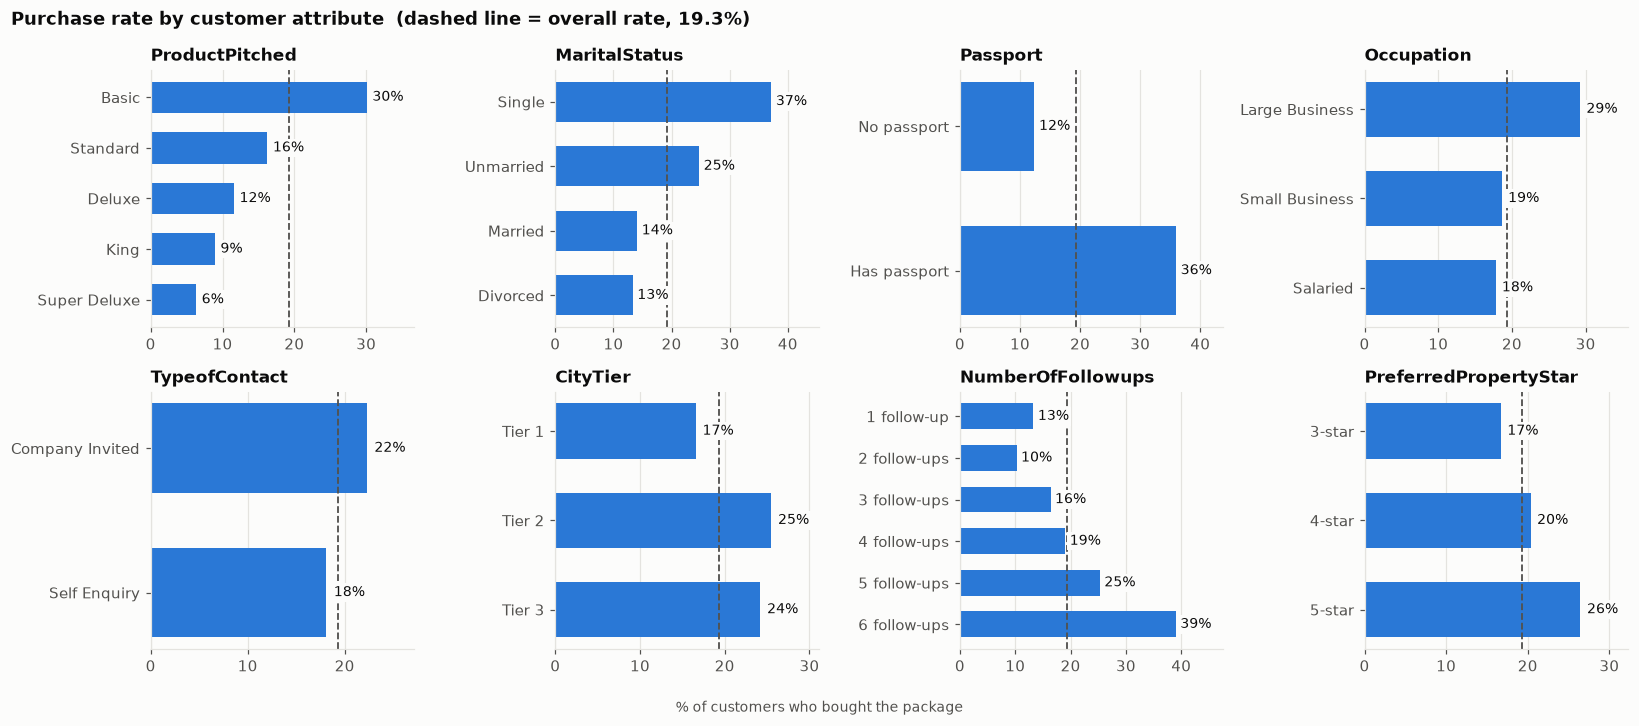

In [5]:
panels = ["ProductPitched", "MaritalStatus", "Passport", "Occupation",
          "TypeofContact", "CityTier", "NumberOfFollowups", "PreferredPropertyStar"]
ORDINAL = {"Passport", "CityTier", "NumberOfFollowups", "PreferredPropertyStar"}   # keep natural order

def pretty(col, v):
    if col == "Passport":
        return "Has passport" if v == 1 else "No passport"
    if col == "CityTier":
        return f"Tier {v}"
    if col == "NumberOfFollowups":
        return f"{v:g} follow-up" + ("" if v == 1 else "s")
    if col == "PreferredPropertyStar":
        return f"{v:g}-star"
    return str(v)

fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
for ax, col in zip(axes.ravel(), panels):
    g = cleaned.groupby(col)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= 30]                             # groups under 30 rows give meaningless rates
    g = g.sort_index(ascending=False) if col in ORDINAL else g.sort_values("mean")
    ax.barh([pretty(col, v) for v in g.index], g["mean"] * 100, color=BLUE, height=0.62)
    ax.axvline(base_rate * 100, color=MUTED, lw=1.2, ls="--")
    for y, rate in enumerate(g["mean"]):
        ax.text(rate * 100 + 0.8, y, f"{rate:.0%}", va="center", fontsize=9,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_title(col)
    ax.set_xlim(0, g["mean"].max() * 100 * 1.22)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Purchase rate by customer attribute  (dashed line = overall rate, {base_rate:.1%})",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.supxlabel("% of customers who bought the package", fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

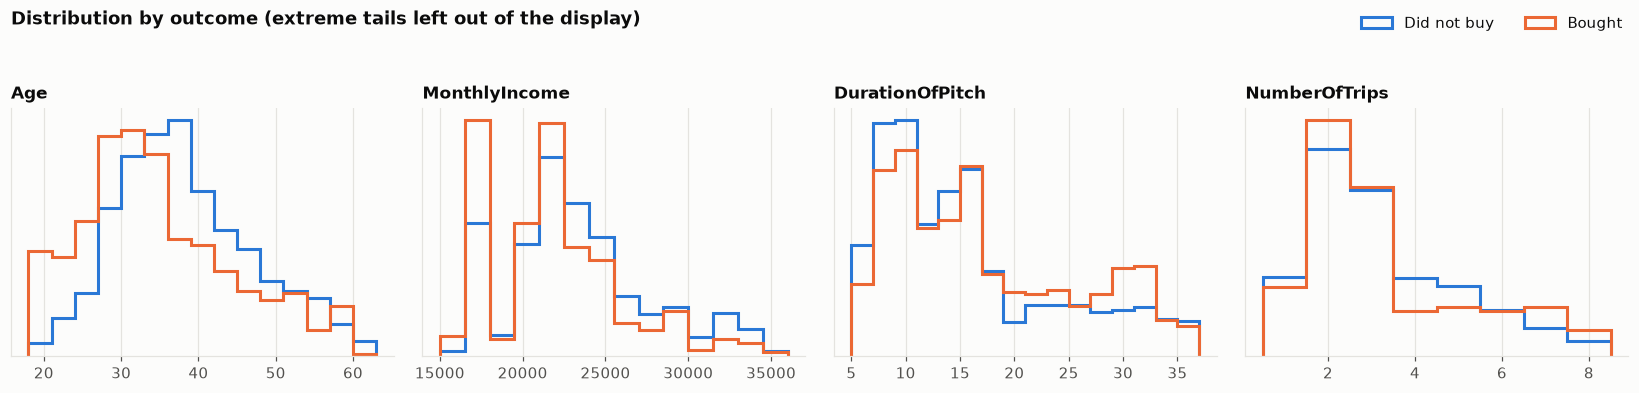

                       Age  MonthlyIncome  DurationOfPitch  NumberOfTrips
ProdTaken                                                                
Did not buy (median)  37.0        22765.0             13.0            3.0
Bought (median)       32.0        21269.5             15.0            3.0


In [6]:
BINS = {"Age": np.arange(18, 64, 3), "MonthlyIncome": np.arange(15000, 36001, 1500),
        "DurationOfPitch": np.arange(5, 38, 2), "NumberOfTrips": np.arange(0.5, 9.5, 1)}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (col, bins) in zip(axes, BINS.items()):
    in_range = cleaned[(cleaned[col] >= bins[0]) & (cleaned[col] <= bins[-1])]   # tails left out of the display
    for outcome, colour, label in ((0, BLUE, "Did not buy"), (1, ORANGE, "Bought")):
        ax.hist(in_range.loc[in_range[TARGET] == outcome, col], bins=bins, density=True,
                histtype="step", linewidth=2, color=colour, label=label)
    ax.set_title(col)
    ax.set_yticks([])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Distribution by outcome (extreme tails left out of the display)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

print(cleaned.groupby(TARGET)[["Age", "MonthlyIncome", "DurationOfPitch", "NumberOfTrips"]].median()
      .rename(index={0: "Did not buy (median)", 1: "Bought (median)"}))

**What separates buyers from non-buyers**

* **Age is a strong signal.** Customers aged 25 or under buy at about 44%, against 11% for ages 35 to 40.
  Buyers have a median age of 32 versus 37 for non-buyers.
* **Passport holders buy at about 36%, against 12% without one.** Passport ownership is a proxy for travel appetite.
* **Single customers buy at about 37%**, versus 13 to 14% for married and divorced customers.
* **Basic (Executive) is the easiest product to sell at 30%**; Super Deluxe (AVP) and King (VP) convert at 6% and 9%.
* **More follow-ups go with more purchases**: 39% at six follow-ups versus 10 to 13% at one or two. This is
  association, not proof of cause, since salespeople may chase the customers who already look interested.
* **Pitch satisfaction score has only a weak simple link to buying** (16% at score 1 versus 22% at score 5), and the
  income difference between buyers and non-buyers is small. A weak one-at-a-time link does not mean a feature is useless
  to a model, which can use it in combination with other fields (see the importance chart in section 4).

## 3. Data preparation

`src/prepare_data.py` loads the CSV straight from the repository `data/` folder and applies the cleaning decisions
from section 2:

1. Drop `Unnamed: 0` and `CustomerID` (no predictive information).
2. Trim whitespace in text columns and correct `Fe Male` to `Female`.
3. Drop rows with a missing target and exact duplicates.
4. Create a **stratified** 80/20 train/test split with a fixed seed, so both parts keep the 19.3% purchase rate
   and the split is reproducible.
5. Save `train.csv` and `test.csv` to `data/processed/`. In GitHub Actions this folder is uploaded as the
   `prepared-data` workflow artifact and downloaded by the model-building job.

Missing values are not filled here. Imputation lives inside the model pipeline (section 4), so it is learned from
the training data only and also protects the deployed app from incomplete input.

In [7]:
run_script("prepare_data.py")

Loaded tourism.csv: 4128 rows x 21 columns
After cleaning: 4011 rows x 19 columns
Dropped columns: ['Unnamed: 0', 'CustomerID']
Gender values: ['Female', 'Male']

Saved to /Users/Phani.Kumar/CBRE/GrateLearning/Tourism Package Predection/tourism-package-prediction/data/processed
  train.csv: 3208 rows, 0.193 positive rate
  test.csv: 803 rows, 0.193 positive rate



In [8]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

overlap = len(train.merge(test, how="inner"))
print(f"Rows present in both train and test: {overlap}  (must be 0, otherwise the test score is inflated)")
assert overlap == 0
print(f"Columns kept ({train.shape[1]}): {list(train.columns)}\n")

summary_table = pd.DataFrame({
    "rows": [len(train), len(test)],
    "buyers": [int(train[TARGET].sum()), int(test[TARGET].sum())],
    "purchase rate": [f"{train[TARGET].mean():.1%}", f"{test[TARGET].mean():.1%}"],
}, index=["train", "test"])
display(summary_table)
print("Saved files:", [f"{p.name} ({p.stat().st_size / 1024:.0f} KB)" for p in sorted(PROCESSED_DIR.glob('*.csv'))])
display(train.head())

Rows present in both train and test: 0  (must be 0, otherwise the test score is inflated)
Columns kept (19): ['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome']



,rows,buyers,purchase rate
train,3208,619,19.3%
test,803,155,19.3%


Saved files: ['test.csv (81 KB)', 'train.csv (322 KB)']


,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,31.0,Self Enquiry,1,17.0,Salaried,Male,2,3.0,Basic,3.0,Divorced,4.0,1,3,1,1.0,Executive,17356.0
1,1,38.0,Self Enquiry,1,18.0,Small Business,Female,4,6.0,Deluxe,4.0,Divorced,7.0,0,4,1,1.0,Manager,23455.0
2,0,28.0,Self Enquiry,1,13.0,Salaried,Male,3,5.0,Basic,3.0,Divorced,3.0,0,2,1,2.0,Executive,21217.0
3,0,37.0,Self Enquiry,1,20.0,Salaried,Female,3,3.0,Basic,5.0,Married,2.0,0,4,1,0.0,Executive,18034.0
4,0,46.0,Self Enquiry,3,27.0,Salaried,Female,3,4.0,Deluxe,3.0,Unmarried,2.0,0,1,1,1.0,Manager,23528.0


## 4. Model building and experiment tracking

**Approach**

* **Preprocessing** (inside the model pipeline, fitted on training data only): median imputation for numeric
  columns, most-frequent imputation and one-hot encoding for categorical columns. Unseen categories are ignored
  rather than crashing the app.
* **Six model families**, as allowed by the brief: Decision Tree, Bagging, Random Forest, AdaBoost, Gradient
  Boosting and XGBoost. Class imbalance is handled with class weights (or `scale_pos_weight` for XGBoost) where the
  algorithm supports it.
* **Tuning:** 20 randomized-search trials per model (fewer for AdaBoost, whose grid has only 16 combinations),
  scored by **F1** with 5-fold stratified cross-validation. F1 balances catching buyers (recall) against wasting
  calls (precision).
* **Selection without peeking:** the best model is chosen on cross-validated F1 over the **training** data only. The
  test set is used afterwards for reporting, so it cannot influence the choice.
* **Experiment tracking with MLflow:** a parent run for the pipeline, one child run per model family, and one grandchild
  run for **every parameter set tried**, each logging its parameters and CV score. Test metrics are logged on the
  model runs.
* **Output:** the winning pipeline (preprocessing plus estimator) is saved to `models/best_model.joblib`, alongside
  `metrics.json` and `feature_schema.json`. The GitHub Actions job commits these to the repository.

This notebook runs the same training script as the pipeline, but saves its output to a **temporary folder**, so it can
never overwrite the model the pipeline committed to `models/`. That committed model is evaluated further below.

In [9]:
import tempfile
LOCAL_RUN = Path(tempfile.mkdtemp(prefix="notebook_run_"))
run_script("train_model.py", "--model-dir", str(LOCAL_RUN))

Loaded train (3208, 19), test (803, 19) from /Users/Phani.Kumar/CBRE/GrateLearning/Tourism Package Predection/tourism-package-prediction/data/processed
DecisionTree      cv_f1=0.6360  test_f1=0.7295  test_recall=0.7742  test_auc=0.8622
Bagging           cv_f1=0.6956  test_f1=0.7807  test_recall=0.6774  test_auc=0.9684
RandomForest      cv_f1=0.7898  test_f1=0.8599  test_recall=0.8516  test_auc=0.9756
AdaBoost          cv_f1=0.4550  test_f1=0.3871  test_recall=0.2710  test_auc=0.8028
GradientBoosting  cv_f1=0.7113  test_f1=0.6772  test_recall=0.5548  test_auc=0.9230
XGBoost           cv_f1=0.7883  test_f1=0.8418  test_recall=0.8065  test_auc=0.9652

Selected model (best CV f1): RandomForest
Saved best_model.joblib, metrics.json, feature_schema.json to /var/folders/j9/xjsjf2g160g6zm5x6xq41sz00000gp/T/notebook_run_ut032m3i



### Experiment tracking: what MLflow recorded

In [10]:
import mlflow

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DIR / 'mlflow.db'}")
runs = mlflow.search_runs(experiment_names=["tourism-package-prediction"])
is_child = runs["tags.mlflow.parentRunId"].notna()
model_runs = runs[runs["params.model_family"].notna()]
trial_runs = runs[runs["tags.mlflow.runName"].str.startswith("trial-", na=False)]

print(f"MLflow runs recorded : {len(runs)}  (1 pipeline run + {len(model_runs)} model runs + {len(trial_runs)} tuning trials)")
param_cols = [c for c in runs.columns if c.startswith("params.")]
print(f"Parameter values logged: {int(runs[param_cols].notna().sum().sum())}")

cols = ["params.model_family", "metrics.cv_f1", "metrics.test_accuracy", "metrics.test_precision",
        "metrics.test_recall", "metrics.test_f1", "metrics.test_roc_auc"]
tracked = (model_runs[cols].rename(columns=lambda c: c.split(".")[-1])
           .sort_values("cv_f1", ascending=False).round(3).reset_index(drop=True))
print("\nOne run per model family (best parameters found, CV score, test metrics):")
display(tracked)

MLflow runs recorded : 123  (1 pipeline run + 6 model runs + 116 tuning trials)
Parameter values logged: 509

One run per model family (best parameters found, CV score, test metrics):


,model_family,cv_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,RandomForest,0.790,0.946,0.868,0.852,0.860,0.976
1,XGBoost,0.788,0.941,0.880,0.806,0.842,0.965
2,GradientBoosting,0.711,0.898,0.869,0.555,0.677,0.923
3,Bagging,0.696,0.927,0.921,0.677,0.781,0.968
4,DecisionTree,0.636,0.889,0.690,0.774,0.729,0.862
5,AdaBoost,0.455,0.834,0.677,0.271,0.387,0.803


In [11]:
local = json.loads((LOCAL_RUN / "metrics.json").read_text())
local_best = local["selected_model"]

print(f"Best parameters per model (logged as MLflow params and saved in metrics.json):")
for name, res in sorted(local["models"].items(), key=lambda kv: -kv[1]["cv_f1"]):
    print(f"  {name:<17} {res['best_params']}")

# Every trial the search ran for the selected model, best first.
parent_id = model_runs.loc[model_runs["params.model_family"] == local_best, "run_id"].iloc[0]
trials = trial_runs[trial_runs["tags.mlflow.parentRunId"] == parent_id]
trial_table = (trials[[c for c in trials.columns if c.startswith("params.") or c == "metrics.cv_f1"]]
               .dropna(axis=1, how="all").rename(columns=lambda c: c.split(".")[-1])
               .sort_values("cv_f1", ascending=False).round(4).reset_index(drop=True))
print(f"\nTop 8 of {len(trial_table)} tuning trials for {local_best}:")
display(trial_table.head(8))

Best parameters per model (logged as MLflow params and saved in metrics.json):
  RandomForest      {'class_weight': 'balanced', 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 200}
  XGBoost           {'colsample_bytree': 0.6, 'learning_rate': 0.05, 'max_depth': 9, 'n_estimators': 200, 'scale_pos_weight': 4.18, 'subsample': 1.0}
  GradientBoosting  {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.85}
  Bagging           {'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 100}
  DecisionTree      {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 2}
  AdaBoost          {'learning_rate': 1.0, 'n_estimators': 300}

Top 8 of 20 tuning trials for RandomForest:


,cv_f1,n_estimators,max_depth,min_samples_leaf,class_weight,max_features
0,0.7898,200,None,1,balanced,0.5
1,0.7808,300,None,1,balanced,0.5
2,0.7790,100,20,1,balanced,0.5
3,0.7648,100,None,1,balanced,sqrt
4,0.7398,100,10,2,balanced,0.5
5,0.7396,200,None,2,balanced,sqrt
6,0.7123,100,10,1,balanced,sqrt
7,0.7103,200,None,2,balanced_subsample,0.5


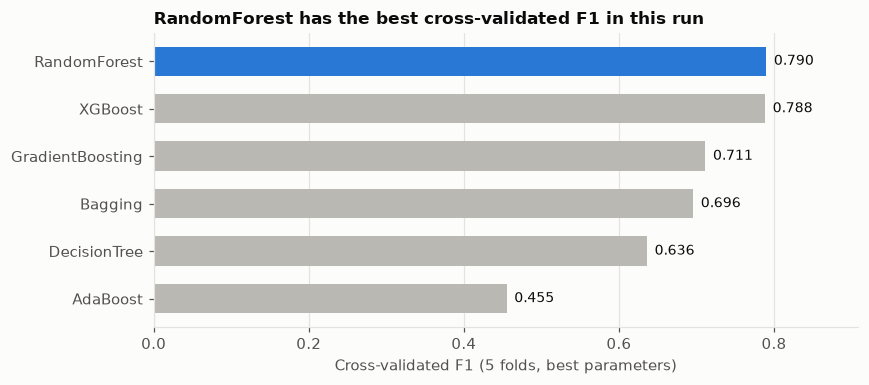

In [12]:
order = sorted(local["models"], key=lambda n: local["models"][n]["cv_f1"])
cv = [local["models"][n]["cv_f1"] for n in order]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(order, cv, color=[BLUE if n == local_best else GRAY for n in order], height=0.62)
for y, v in enumerate(cv):
    ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, max(cv) * 1.15)
ax.set_title(f"{local_best} has the best cross-validated F1 in this run")
ax.set_xlabel("Cross-validated F1 (5 folds, best parameters)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### The model that is actually deployed

The app serves whatever model the **GitHub Actions run** committed to `models/`, not this notebook's run. Training runs on a
different machine (Linux in CI, macOS here), and tiny floating-point differences can shift cross-validation scores by a few
thousandths. When two models are that close, the winner can differ between runs. Here is the committed model's
record next to this notebook's run.

In [13]:
summary = json.loads(METRICS_PATH.read_text())          # models/metrics.json: written by the pipeline
best_name = summary["selected_model"]

compare = pd.DataFrame({
    "CV F1 (this notebook)": {m: r["cv_f1"] for m, r in local["models"].items()},
    "CV F1 (committed by pipeline)": {m: r["cv_f1"] for m, r in summary["models"].items()},
    "test F1 (this notebook)": {m: r["test"]["f1"] for m, r in local["models"].items()},
    "test F1 (committed by pipeline)": {m: r["test"]["f1"] for m, r in summary["models"].items()},
}).sort_values("CV F1 (committed by pipeline)", ascending=False).round(3)
display(compare)

gap = (summary["models"][best_name]["cv_f1"] - summary["models"][local_best]["cv_f1"]) if local_best != best_name else 0.0
if local_best == best_name:
    display(Markdown(f"Both runs selected **{best_name}**, so the deployed model matches this notebook's experiment."))
else:
    display(Markdown(
        f"This notebook's run selected **{local_best}**, while the pipeline's run selected **{best_name}**. "
        f"In the pipeline's own scores the two differ by only {abs(gap):.3f} CV F1, well inside run-to-run noise, so they are "
        f"effectively tied. **The deployed model is {best_name}**, and every evaluation below is of that committed model."))

,CV F1 (this notebook),CV F1 (committed by pipeline),test F1 (this notebook),test F1 (committed by pipeline)
XGBoost,0.788,0.795,0.842,0.834
RandomForest,0.790,0.787,0.860,0.830
GradientBoosting,0.711,0.715,0.677,0.690
Bagging,0.696,0.691,0.781,0.762
DecisionTree,0.636,0.635,0.729,0.727
AdaBoost,0.455,0.455,0.387,0.387


This notebook's run selected **RandomForest**, while the pipeline's run selected **XGBoost**. In the pipeline's own scores the two differ by only 0.008 CV F1, well inside run-to-run noise, so they are effectively tied. **The deployed model is XGBoost**, and every evaluation below is of that committed model.

### Evaluating the deployed model on the held-out test set

Selected model: XGBoost

              precision    recall  f1-score   support

 No purchase      0.949     0.978     0.964       648
    Purchase      0.896     0.781     0.834       155

    accuracy                          0.940       803
   macro avg      0.923     0.880     0.899       803
weighted avg      0.939     0.940     0.939       803



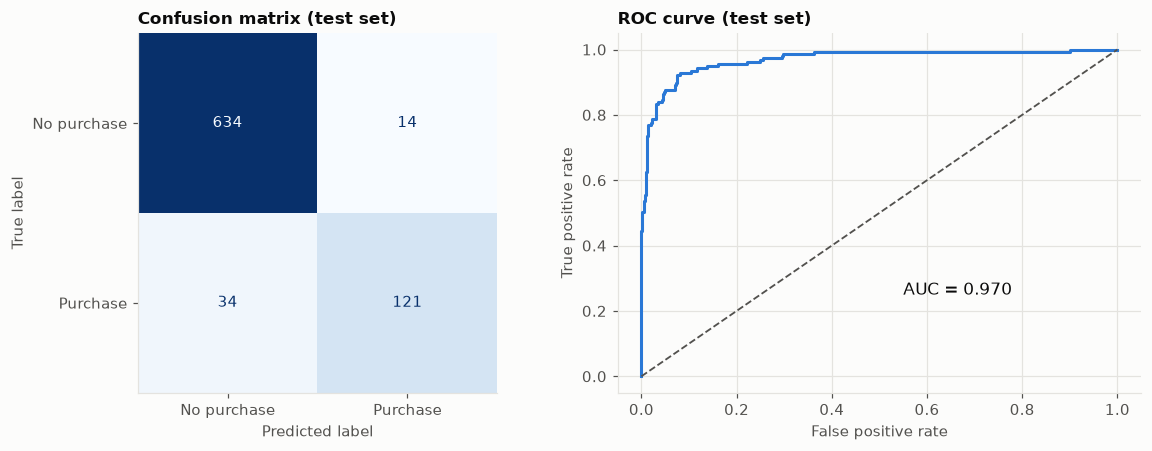

In [14]:
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, roc_auc_score,
                             roc_curve)

# joblib unpickles code: safe here because this is the model our own pipeline just wrote.
best = joblib.load(MODEL_PATH)
X_test, y_test = test[FEATURES], test[TARGET]
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"Selected model: {best_name}\n")
print(classification_report(y_test, pred, target_names=["No purchase", "Purchase"], digits=3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No purchase", "Purchase"],
                                        cmap="Blues", colorbar=False, ax=ax1)
ax1.grid(False)
ax1.set_title("Confusion matrix (test set)")

fpr, tpr, _ = roc_curve(y_test, proba)
ax2.plot(fpr, tpr, color=BLUE, lw=2)
ax2.plot([0, 1], [0, 1], color=MUTED, lw=1.2, ls="--")
ax2.text(0.55, 0.25, f"AUC = {roc_auc_score(y_test, proba):.3f}", fontsize=11)
ax2.set_xlabel("False positive rate")
ax2.set_ylabel("True positive rate")
ax2.set_title("ROC curve (test set)")
plt.tight_layout()
plt.show()

### Which features does the model rely on?

Tree-based "impurity" importances over-credit noisy, many-valued columns, so we use **permutation importance** on the
test set instead: shuffle one column, and measure how much the F1 score drops. A bigger drop means the model leans on
that column more. Because the pipeline handles encoding, each original column is shuffled as a whole.

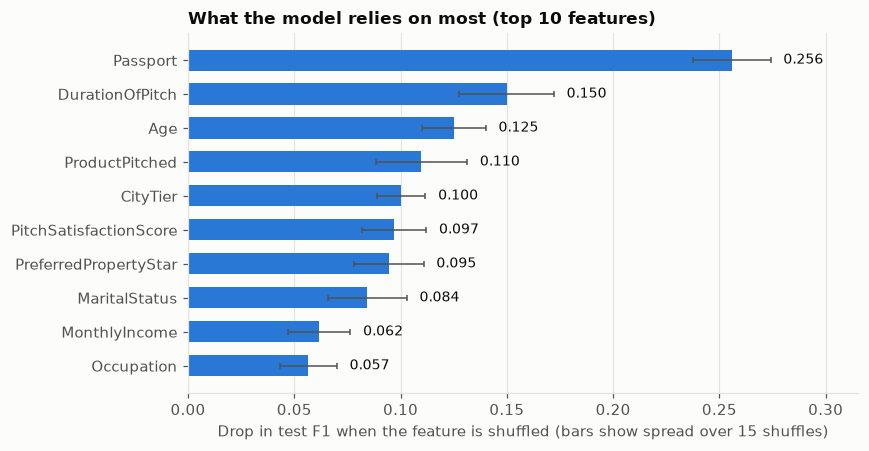

The five columns the model leans on most are `Passport`, `DurationOfPitch`, `Age`, `ProductPitched`, `CityTier`. Importance shows what the model **uses**, not what **causes** a purchase. It also includes columns like pitch duration, age and income, whose exact values can help the model recognise a customer it has effectively seen before (see the check below).

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best, X_test, y_test, scoring="f1", n_repeats=15,
                              random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=FEATURES)
spread = pd.Series(perm.importances_std, index=FEATURES)
top = importance.nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, top.values, xerr=spread[top.index].values, color=BLUE, height=0.62,
        error_kw=dict(ecolor=MUTED, lw=1, capsize=2))
for y, v in enumerate(top.values):
    ax.text(v + spread[top.index].iloc[y] + 0.006, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, (top + spread[top.index]).max() * 1.15)
ax.set_title("What the model relies on most (top 10 features)")
ax.set_xlabel("Drop in test F1 when the feature is shuffled (bars show spread over 15 shuffles)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

leaders = ", ".join(f"`{name}`" for name in importance.nlargest(5).index)
display(Markdown(f"The five columns the model leans on most are {leaders}. Importance shows what the model **uses**, "
                 "not what **causes** a purchase. It also includes columns like pitch duration, age and income, whose exact "
                 "values can help the model recognise a customer it has effectively seen before (see the check below)."))

### Sensitivity check: can the model work *before* the customer is contacted?

The business goal is to predict purchases **before contacting** a customer. But four columns only exist **after** a
sales pitch has happened: `ProductPitched`, `NumberOfFollowups`, `DurationOfPitch` and `PitchSatisfactionScore`. The
data dictionary lists them as inputs, so the deployed model uses them, but it is worth measuring how much of the
score depends on them. `Designation` is a customer attribute and is kept (it already carries the same information
as `ProductPitched`). We refit the same algorithm with the same parameters without the four pitch columns.

In [16]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from train_model import evaluate

PITCH = ["ProductPitched", "NumberOfFollowups", "DurationOfPitch", "PitchSatisfactionScore"]
num = [c for c in NUMERIC_FEATURES if c not in PITCH]
cat = [c for c in CATEGORICAL_FEATURES if c not in PITCH]

pre_contact = Pipeline([
    ("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ])),
    ("model", clone(best.named_steps["model"])),
]).fit(train[num + cat], train[TARGET])

comparison = pd.DataFrame({
    "Deployed model (all 18 features)": evaluate(best, X_test, y_test),
    "Pre-contact model (14 features)": evaluate(pre_contact, test[num + cat], y_test),
}).T.round(3)
display(comparison)

,accuracy,precision,recall,f1,roc_auc
Deployed model (all 18 features),0.940,0.896,0.781,0.834,0.970
Pre-contact model (14 features),0.917,0.828,0.716,0.768,0.928


### How far can we trust the test score? A near-duplicate check

Section 3 removed rows that were identical on every feature. But customers can also be *nearly* identical: the same
person recorded twice with a small change, for example. If a test customer has such a "twin" in the training data, the
model can score well by recognising the twin rather than by learning general patterns. We measure this: for each test
customer, find the training customer who matches on the most of the 18 features, and count a **near-twin** as a match on
16 or more.

In [17]:
from sklearn.metrics import f1_score, precision_score, recall_score

train_values = train[FEATURES].to_numpy(dtype=object)
test_values = test[FEATURES].to_numpy(dtype=object)
matches = np.zeros((len(test_values), len(train_values)), dtype=np.int16)
for j in range(len(FEATURES)):
    matches += test_values[:, [j]] == train_values[:, j][None, :]      # columns on which the two customers agree

has_twin = matches.max(axis=1) >= 16
closest_label = train[TARGET].to_numpy()[matches.argmax(axis=1)]
twin_share = has_twin.mean()
twin_agree = (closest_label == y_test.to_numpy())[has_twin].mean()

def scores(mask, predictions=pred):
    y, p = y_test.to_numpy()[mask], predictions[mask]
    return {"customers": int(mask.sum()), "buyers": int(y.sum()), "precision": precision_score(y, p),
            "recall": recall_score(y, p), "f1": f1_score(y, p)}

twin_table = pd.DataFrame({
    "All test customers": scores(np.ones(len(y_test), dtype=bool)),
    "Has a near-twin in training data": scores(has_twin),
    "No near-twin (like a new customer)": scores(~has_twin),
}).T
no_twin = twin_table.loc["No near-twin (like a new customer)"]

# If this notebook's own run picked a different model, score it on the same customers for comparison.
alt_no_twin = None
if local_best != best_name:
    # joblib unpickles code: safe, this is the model the notebook's own training run just wrote.
    alt_model = joblib.load(LOCAL_RUN / "best_model.joblib")
    alt_pred = (alt_model.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    alt_no_twin = scores(~has_twin, alt_pred)
    twin_table.loc[f"{local_best} (this notebook's run): no near-twin"] = alt_no_twin

twin_table[["customers", "buyers"]] = twin_table[["customers", "buyers"]].astype(int)
display(twin_table.round(3))

print(f"{twin_share:.0%} of test customers have a near-twin in the training data, and the twin has the same outcome "
      f"{twin_agree:.0%} of the time.")

,customers,buyers,precision,recall,f1
All test customers,803,155,0.896,0.781,0.834
Has a near-twin in training data,338,72,1.000,1.000,1.000
No near-twin (like a new customer),465,83,0.778,0.590,0.671
RandomForest (this notebook's run): no near-twin,465,83,0.792,0.735,0.762


42% of test customers have a near-twin in the training data, and the twin has the same outcome 100% of the time.


**Reading the result.** Customers with a near-twin are predicted almost perfectly, because the model has effectively seen
them. Customers *without* a twin are the better stand-in for the real situation: a brand-new customer the sales team is
about to call. On those, the scores are clearly lower than the headline numbers, so the realistic expectation is the
bottom row, not the top row. The headline test score (and the cross-validation scores used to pick the model) are therefore
optimistic. The model is still useful, but this is the figure to quote when judging how many buyers it will find.
A stricter pipeline would group near-identical customers together before splitting; that is listed under next steps.

## 5. Model deployment (Streamlit)

The app (`app.py`) loads the model that the pipeline committed to `models/` and has two tabs:

* **Single Prediction.** A form collects the customer and pitch details. A summary column beside the form updates live as the
  inputs change. Pressing *Predict* saves the inputs into a one-row **dataframe** whose columns match the training data, and shows
  the purchase probability with a plain-language verdict.
* **Batch Prediction.** The sales team uploads a CSV of customers and gets every row scored and ranked by probability, ready to
  download. The upload is validated first: missing columns are named in an error, the known `Fe Male` spelling is corrected, and
  unseen values or blanks produce a warning instead of a silent wrong answer.

The sidebar shows which algorithm is deployed and its test scores. Input choices and default selections come from
`models/feature_schema.json`, which the training job regenerates, so the form stays consistent with the model. The loading and
cleaning logic lives in `inference.py`, separate from the screen code, so it can be tested without a browser.

The deployment dependencies are in `requirements.txt`, pinned to the exact versions used for training so the saved model loads
identically in CI and in production. The app is hosted on **Streamlit Community Cloud**, which reads the repository on GitHub
and redeploys automatically when a new commit arrives.

In [18]:
display(Markdown("**app.py**\n\n```python\n" + (REPO / "app.py").read_text() + "```"))
display(Markdown("**inference.py**\n\n```python\n" + (REPO / "inference.py").read_text() + "```"))
display(Markdown("**requirements.txt**\n\n```text\n" + (REPO / "requirements.txt").read_text() + "```"))

**app.py**

```python
"""Streamlit app: will this customer buy the Wellness Tourism Package?

Loads the model the MLOps pipeline committed to models/. Score one customer from a
form (Single Prediction) or a whole customer list from a CSV (Batch Prediction).
"""
import pandas as pd
import streamlit as st

from inference import (THRESHOLD, label, load_artifacts, prepare_batch,
                       required_columns, unseen_pairs)

MAX_BATCH_ROWS = 20_000

st.set_page_config(page_title="Wellness Tourism Package Predictor", page_icon="🧳",
                   layout="wide")


@st.cache_resource
def get_artifacts():
    return load_artifacts()


def yes_no(text: str, default: str = "No") -> int:
    return 1 if st.selectbox(text, ["No", "Yes"], index=["No", "Yes"].index(default)) == "Yes" else 0


def pick(text: str, column: str) -> str:
    """Dropdown over a column's known values, starting on its most common one."""
    return st.selectbox(text, choices[column], index=choices[column].index(default[column]))


try:
    model, schema, metrics = get_artifacts()
except FileNotFoundError:
    st.error("Model files not found in models/. Run the training pipeline first.")
    st.stop()

median = {c: v["median"] for c, v in schema["numeric"].items()}
choices = schema["categorical"]
# Most common training value per column; older schema files without it fall back to the first choice.
common = schema.get("categorical_mode", {})
default = {c: common.get(c, choices[c][0]) for c in choices}
best = metrics["selected_model"]
test = metrics["models"][best]["test"]

# ---------------------------------------------------------------- sidebar
with st.sidebar:
    st.title("🧳 Visit with Us")
    st.subheader("Customer Targeting System")
    st.write(f"Predicts how likely a customer is to buy the **Wellness Tourism Package** "
             f"using a trained **{best}** model, so the sales team can prioritise who to contact.")
    st.divider()
    st.subheader("Model scores")
    for name, text in (("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"),
                       ("f1", "F1"), ("roc_auc", "ROC-AUC")):
        st.metric(text, f"{test[name]:.3f}")
    st.caption("Scores on a held-out test set. The model is trained and committed "
               "automatically by the GitHub Actions pipeline.")
    st.divider()
    st.write("Built with **Streamlit**")

# ---------------------------------------------------------------- main
st.title("🧳 Wellness Tourism Package Predictor")
st.write("Estimate whether a customer will buy the Wellness Tourism Package. "
         "Use **Single Prediction** for one customer or **Batch Prediction** for a CSV file.")

single_tab, batch_tab = st.tabs(["📊 Single Prediction", "📁 Batch Prediction"])

# ---- single prediction
with single_tab:
    st.header("Enter customer details")
    customer, trip, sales, summary = st.columns([1, 1, 1, 0.8], gap="large")

    with customer:
        st.subheader("Customer")
        age = st.number_input("Age", 18, 100, int(median["Age"]))
        gender = pick("Gender", "Gender")
        marital = pick("Marital status", "MaritalStatus")
        occupation = pick("Occupation", "Occupation")
        designation = pick("Designation", "Designation")
        income = st.number_input("Monthly income", 1000, 500000,
                                 int(median["MonthlyIncome"]), step=500)
        city_tier = st.selectbox("City tier", [1, 2, 3], index=0)

    with trip:
        st.subheader("Trip preferences")
        persons = st.number_input("Number of people visiting", 1, 10,
                                  int(median["NumberOfPersonVisiting"]))
        children = st.number_input("Children under 5 visiting", 0, 5,
                                   int(median["NumberOfChildrenVisiting"]))
        trips = st.number_input("Trips per year", 0, 30, int(median["NumberOfTrips"]))
        star = st.selectbox("Preferred property star", [3, 4, 5], index=0)
        passport = yes_no("Holds a valid passport")
        own_car = yes_no("Owns a car", default="Yes")

    with sales:
        st.subheader("Sales interaction")
        contact = pick("Type of contact", "TypeofContact")
        product = pick("Product pitched", "ProductPitched")
        duration = st.number_input("Duration of pitch (minutes)", 1, 200,
                                   int(median["DurationOfPitch"]))
        followups = st.number_input("Number of follow-ups", 0, 10,
                                    int(median["NumberOfFollowups"]))
        satisfaction = st.slider("Pitch satisfaction score", 1, 5,
                                 int(median["PitchSatisfactionScore"]))

    with summary:
        st.subheader("Summary")
        st.metric("Age", age)
        st.metric("Monthly income", f"{income:,}")
        st.metric("Product pitched", product)
        st.metric("Travelling party", persons)
        st.metric("Passport", "Yes" if passport else "No")

    if st.button("Predict", type="primary"):
        # Column names must match the training data exactly.
        inputs = pd.DataFrame([{
            "Age": age, "CityTier": city_tier, "DurationOfPitch": duration,
            "NumberOfPersonVisiting": persons, "NumberOfFollowups": followups,
            "PreferredPropertyStar": star, "NumberOfTrips": trips, "Passport": passport,
            "PitchSatisfactionScore": satisfaction, "OwnCar": own_car,
            "NumberOfChildrenVisiting": children, "MonthlyIncome": income,
            "TypeofContact": contact, "Occupation": occupation, "Gender": gender,
            "ProductPitched": product, "MaritalStatus": marital, "Designation": designation,
        }])

        st.subheader("Input summary")
        st.dataframe(inputs, hide_index=True, width="stretch")

        probability = float(model.predict_proba(inputs)[0, 1])
        st.subheader("Prediction")
        if unseen_pairs(inputs, schema).iloc[0]:
            st.warning(f"No customer with designation '{designation}' was ever pitched "
                       f"'{product}' in the training data, so treat this score with caution.")
        st.metric("Purchase probability", f"{probability:.1%}")
        st.progress(probability)
        if probability >= THRESHOLD:
            st.success("Likely to purchase the Wellness Tourism Package. Worth prioritising.")
        else:
            st.info("Unlikely to purchase the Wellness Tourism Package.")

# ---- batch prediction
with batch_tab:
    st.header("Score a customer list")
    columns = required_columns(schema)
    st.write("Upload a CSV with one row per customer. The file needs these columns; any extra "
             "columns (such as CustomerID) are kept in the output.")
    st.code(", ".join(columns), language="text", wrap_lines=True)

    template = pd.DataFrame([{**{c: int(median[c]) for c in schema["numeric"]},
                              **{c: default[c] for c in choices}}])[columns]
    st.download_button("Download a template CSV", template.to_csv(index=False).encode(),
                       file_name="customers_template.csv", mime="text/csv")

    upload = st.file_uploader("Upload customer CSV", type="csv")
    if upload is not None:
        try:
            data = pd.read_csv(upload)
        except (pd.errors.ParserError, pd.errors.EmptyDataError, UnicodeDecodeError) as err:
            st.error(f"Could not read that file as a CSV: {err}")
            data = None

        if data is not None and data.empty:
            st.error("The file has no rows.")
        elif data is not None and len(data) > MAX_BATCH_ROWS:
            st.error(f"Please upload at most {MAX_BATCH_ROWS:,} rows at a time "
                     f"(this file has {len(data):,}).")
        elif data is not None:
            try:
                features, notes = prepare_batch(data, schema)
            except ValueError as err:
                st.error(str(err))
            else:
                for note in notes:
                    st.warning(note)
                probabilities = model.predict_proba(features)[:, 1]
                results = data.copy()
                results.insert(0, "Prediction", label(probabilities))
                results.insert(0, "PurchaseProbability", probabilities.round(4))   # leftmost: the signal to act on
                results = results.sort_values("PurchaseProbability", ascending=False)

                likely = int((probabilities >= THRESHOLD).sum())
                total, share, top = st.columns(3)
                total.metric("Customers scored", f"{len(results):,}")
                share.metric("Likely buyers", f"{likely:,}")
                top.metric("Share likely to buy", f"{likely / len(results):.1%}")

                st.subheader("Results (highest probability first)")
                st.dataframe(results, hide_index=True, width="stretch", column_config={
                    "PurchaseProbability": st.column_config.ProgressColumn(
                        "PurchaseProbability", min_value=0.0, max_value=1.0, format="%.2f")})
                st.download_button("Download predictions CSV",
                                   results.to_csv(index=False).encode(),
                                   file_name="predictions.csv", mime="text/csv")
```

**inference.py**

```python
"""Model loading and input cleaning shared by the Streamlit app and the tests.

Kept free of Streamlit code so it can be tested without a browser.
"""
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent
MODEL_PATH = ROOT / "models" / "best_model.joblib"
SCHEMA_PATH = ROOT / "models" / "feature_schema.json"
METRICS_PATH = ROOT / "models" / "metrics.json"
THRESHOLD = 0.5  # the cut-off the model was evaluated at

# Spelling variant present in the raw data; training cleans it, so uploads must too.
GENDER_FIXES = {"Fe Male": "Female"}


def load_artifacts():
    """Return (model, schema, metrics) from the files the pipeline committed to models/."""
    # joblib unpickles code, so only load a model we trust. This file is written by
    # our own GitHub Actions pipeline and committed to this repo; never point
    # MODEL_PATH at a file from an external or user-supplied source.
    model = joblib.load(MODEL_PATH)
    schema = json.loads(SCHEMA_PATH.read_text())
    metrics = json.loads(METRICS_PATH.read_text())
    return model, schema, metrics


def required_columns(schema: dict) -> list[str]:
    return list(schema["numeric"]) + list(schema["categorical"])


def unseen_pairs(df: pd.DataFrame, schema: dict) -> pd.Series:
    """True for rows whose Designation/ProductPitched pairing never occurs in training."""
    observed = {tuple(pair) for pair in schema["observed_designation_product"]}
    return pd.Series([(d, p) not in observed
                      for d, p in zip(df["Designation"], df["ProductPitched"])],
                     index=df.index)


def prepare_batch(df: pd.DataFrame, schema: dict) -> tuple[pd.DataFrame, list[str]]:
    """Clean an uploaded table into model input.

    Returns the model-ready columns plus plain-language notes about anything the
    model will treat specially. Raises ValueError if required columns are missing.
    """
    numeric, categorical = list(schema["numeric"]), list(schema["categorical"])
    missing = [c for c in numeric + categorical if c not in df.columns]
    if missing:
        raise ValueError("Missing required column(s): " + ", ".join(missing))

    X = df[numeric + categorical].copy()
    notes = []

    for col in categorical:
        X[col] = X[col].map(lambda v: v.strip() if isinstance(v, str) else v)
    X["Gender"] = X["Gender"].replace(GENDER_FIXES)
    for col in categorical:
        unseen = X[col].notna() & ~X[col].isin(schema["categorical"][col])
        if unseen.any():
            examples = ", ".join(map(repr, sorted(X.loc[unseen, col].astype(str).unique())[:3]))
            notes.append(f"{int(unseen.sum())} row(s) have a value in {col} that the model has not seen "
                         f"({examples}); the model ignores it for those rows.")

    for col in numeric:
        values = pd.to_numeric(X[col], errors="coerce")
        bad = values.isna() & X[col].notna()
        if bad.any():
            notes.append(f"{int(bad.sum())} non-numeric value(s) in {col} were treated as missing.")
        X[col] = values

    blanks = int(X.isna().sum().sum())
    if blanks:
        notes.append(f"{blanks} missing value(s) were filled with the training median "
                     "(numbers) or most common value (categories).")

    odd = unseen_pairs(X, schema)
    if odd.any():
        notes.append(f"{int(odd.sum())} row(s) pair a Designation with a ProductPitched that never occurs "
                     "in the training data; treat those scores with caution.")

    return X.replace({pd.NA: np.nan}), notes


def label(probabilities) -> np.ndarray:
    return np.where(np.asarray(probabilities) >= THRESHOLD, "Likely buyer", "Unlikely buyer")
```

**requirements.txt**

```text
# Deployment dependencies (read by Streamlit Community Cloud).
# Pinned to the versions the model is trained with so the pickled model loads
# identically in CI and in production. Use Python 3.12.
streamlit==1.66.1
pandas==3.1.0
numpy==2.5.4
scipy==1.18.1
scikit-learn==1.9.1
xgboost==3.4.1
joblib==1.6.0
```

**Testing the app without a browser.** Streamlit's `AppTest` drives the real `app.py`: it fills the form, presses
*Predict* and reads the result. We score four customers, including a pairing of designation and product that never
occurs in the training data, to check the warning. A batch upload is tested after that.

In [19]:
from streamlit.testing.v1 import AppTest

logging.disable(logging.CRITICAL)   # Streamlit warns about "bare mode" when tested outside `streamlit run`

def score(label, **inputs):
    at = AppTest.from_file(str(REPO / "app.py"), default_timeout=60).run()
    widgets = {w.label: w for w in list(at.number_input) + list(at.selectbox) + list(at.slider)}
    for name, value in inputs.items():
        widgets[name].set_value(value)
    at.button[0].click().run()
    assert not at.exception, at.exception
    prob = next(m.value for m in at.metric if m.label == "Purchase probability")
    unseen = any("training data" in w.value for w in at.warning)
    return {"Customer": label, "Purchase probability": prob, "Warns: unseen combination": unseen}

examples = [
    score("Typical customer (all defaults)"),
    score("Single, 28, passport, Basic pitch, 5 follow-ups",
          **{"Age": 28, "Marital status": "Single", "Holds a valid passport": "Yes",
             "Product pitched": "Basic", "Designation": "Executive", "Number of follow-ups": 5,
             "Type of contact": "Company Invited"}),
    score("Married, 55, no passport, King pitch",
          **{"Age": 55, "Marital status": "Married", "Holds a valid passport": "No",
             "Product pitched": "King", "Designation": "VP", "Number of follow-ups": 2}),
    score("VP pitched 'Basic' (never seen in training)",
          **{"Designation": "VP", "Product pitched": "Basic"}),
]
display(pd.DataFrame(examples).style.hide(axis="index"))

Customer,Purchase probability,Warns: unseen combination
Typical customer (all defaults),3.1%,False
"Single, 28, passport, Basic pitch, 5 follow-ups",82.0%,False
"Married, 55, no passport, King pitch",1.0%,False
VP pitched 'Basic' (never seen in training),3.7%,True


In [20]:
def upload(frame):
    at = AppTest.from_file(str(REPO / "app.py"), default_timeout=90).run()
    at.file_uploader[0].upload("customers.csv", frame.to_csv(index=False).encode(), "text/csv").run()
    assert not at.exception, at.exception
    return at

# The raw dataset has an index column, a CustomerID, and the 'Fe Male' spelling variant: a realistic upload.
batch = upload(pd.read_csv(RAW_DATA).head(300))
print({m.label: m.value for m in batch.metric if m.label in ("Customers scored", "Likely buyers", "Share likely to buy")})
print("Top of the ranked results:")
display(batch.dataframe[-1].value.head(5)[["PurchaseProbability", "Prediction", "CustomerID", "Age",
                                           "MaritalStatus", "Passport", "ProductPitched"]])

missing_age = upload(pd.read_csv(RAW_DATA).head(5).drop(columns=["Age"]))
print("File with no Age column ->", [e.value for e in missing_age.error])
logging.disable(logging.NOTSET)

{'Customers scored': '300', 'Likely buyers': '44', 'Share likely to buy': '14.7%'}
Top of the ranked results:


,PurchaseProbability,Prediction,CustomerID,Age,MaritalStatus,Passport,ProductPitched
12,0.9967,Likely buyer,200014,28.0,Single,1,Basic
103,0.9948,Likely buyer,200127,19.0,Single,1,Basic
147,0.9929,Likely buyer,200182,41.0,Single,1,Basic
79,0.9899,Likely buyer,200100,37.0,Married,1,Basic
185,0.9898,Likely buyer,200229,29.0,Single,1,Basic


File with no Age column -> ['Missing required column(s): Age']


## 6. MLOps pipeline (GitHub Actions)

`.github/workflows/pipeline.yml` automates the whole workflow. It runs on every push to `main` that changes the data,
the pipeline code, the requirements or the workflow itself, and can also be started by hand (*Run workflow*).

| Job | Needs | What it does |
|---|---|---|
| **1. Register dataset** | none | installs dependencies, runs `validate_data.py`: schema check plus summary |
| **2. Prepare data** | job 1 | runs `prepare_data.py`, uploads `data/processed/` as the `prepared-data` artifact |
| **3. Build and track model** | job 2 | downloads the artifact, runs `train_model.py` (tuning plus MLflow), uploads the MLflow log as an artifact, then **commits `models/` to `main`** as `github-actions[bot]` |
| **4. Verify app** | job 3 | fresh checkout of `main`, installs only the deployment `requirements.txt`, smoke-tests the app (single and batch prediction) against the committed model |

Design choices worth noting:

* **Jobs are chained with `needs`**, so a failed validation stops everything downstream.
* **Data moves between jobs as a workflow artifact**, because each job runs on a fresh machine.
* **The model is committed back to the repository** only when it actually changed, and the push uses
  `git pull --rebase` first so a concurrent push to `main` does not break the run.
* **No infinite loop:** commits pushed with the workflow's `GITHUB_TOKEN` do not trigger new workflow runs, and the
  trigger paths exclude `models/` anyway.
* **Least privilege:** the workflow is read-only by default; only the model job gets `contents: write`.
* **`concurrency`** queues overlapping runs instead of letting them race to push.
* **The last job proves the deployed artifact works**, using exactly the dependencies Streamlit Cloud installs.
* Because each push to `main` that commits a new model also updates the repo Streamlit Cloud watches, the deployed app
  picks up the new model automatically.

In [21]:
display(Markdown("**.github/workflows/pipeline.yml**\n\n```yaml\n"
                 + (REPO / ".github/workflows/pipeline.yml").read_text() + "```"))

**.github/workflows/pipeline.yml**

```yaml
name: MLOps pipeline

# Runs when data, pipeline code, dependencies or this workflow change on main.
# Changes under models/ are deliberately not a trigger: the pipeline commits the
# trained model there itself, and that must not start another run.
on:
  push:
    branches: [main]
    paths:
      - "data/**"
      - "src/**"
      - "requirements*.txt"
      - ".github/workflows/pipeline.yml"
  workflow_dispatch:

# Runs queue instead of racing each other to push the model.
concurrency:
  group: mlops-pipeline
  cancel-in-progress: false

permissions:
  contents: read

env:
  PYTHON_VERSION: "3.12"

jobs:
  register-dataset:
    name: 1. Register dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v7

      - uses: actions/setup-python@v7
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: requirements-train.txt

      - name: Install dependencies
        run: pip install -r requirements-train.txt

      - name: Validate dataset schema and print summary
        run: python src/validate_data.py

  data-prep:
    name: 2. Prepare data
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v7

      - uses: actions/setup-python@v7
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: requirements-train.txt

      - name: Install dependencies
        run: pip install -r requirements-train.txt

      - name: Clean data and create train/test split
        run: python src/prepare_data.py

      - name: Publish train/test split for the next job
        uses: actions/upload-artifact@v7
        with:
          name: prepared-data
          path: data/processed/
          if-no-files-found: error

  model-building:
    name: 3. Build and track model
    needs: data-prep
    runs-on: ubuntu-latest
    permissions:
      contents: write # needed to push the trained model to main
    steps:
      - uses: actions/checkout@v7

      - uses: actions/setup-python@v7
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: requirements-train.txt

      - name: Install dependencies
        run: pip install -r requirements-train.txt

      - name: Download train/test split
        uses: actions/download-artifact@v8
        with:
          name: prepared-data
          path: data/processed

      - name: Tune models and log experiments to MLflow
        run: python src/train_model.py --data-dir data/processed

      - name: Keep the MLflow experiment log
        uses: actions/upload-artifact@v7
        with:
          name: mlflow-runs
          path: mlruns/
          retention-days: 30

      - name: Commit the trained model to main
        if: github.ref == 'refs/heads/main'
        run: |
          git config user.name "github-actions[bot]"
          git config user.email "41898282+github-actions[bot]@users.noreply.github.com"
          git add models/
          if git diff --cached --quiet; then
            echo "Model unchanged, nothing to commit."
          else
            git commit -m "chore(model): update trained model [skip ci]"
            git pull --rebase origin main
            git push origin HEAD:main
          fi

  verify-app:
    name: 4. Verify app with committed model
    needs: model-building
    if: github.ref == 'refs/heads/main'
    runs-on: ubuntu-latest
    steps:
      # Fresh checkout of main so the model committed by the previous job is included.
      - uses: actions/checkout@v7
        with:
          ref: main

      - uses: actions/setup-python@v7
        with:
          python-version: ${{ env.PYTHON_VERSION }}
          cache: pip
          cache-dependency-path: requirements.txt

      # Only the deployment dependencies, exactly what Streamlit Cloud installs.
      - name: Install deployment dependencies
        run: pip install -r requirements.txt

      - name: Smoke-test the Streamlit app
        run: python tests/smoke_test_app.py
```

## 7. Output evaluation: links and screenshots

In [22]:
SHOTS = Path("screenshots")

def show_screenshot(filename, caption):
    display(Markdown(f"**{caption}**"))
    path = SHOTS / filename
    if path.exists():
        display(Image(filename=str(path)))
    else:
        display(Markdown(f"> _Screenshot `{filename}` is added after the repository is pushed and the app is deployed._"))

display(Markdown("\n".join([link("GitHub repository", GITHUB_URL), link("Streamlit app", STREAMLIT_URL)])))
show_screenshot("github_repo_structure.png", "GitHub repository folder structure")
show_screenshot("github_actions_run.png", "Executed GitHub Actions workflow")
show_screenshot("streamlit_app.png", "Deployed Streamlit app")

- **GitHub repository:** [https://github.com/phaniapsr/tourism-package-prediction](https://github.com/phaniapsr/tourism-package-prediction)
- **Streamlit app:** _added after deployment_

**GitHub repository folder structure**

> _Screenshot `github_repo_structure.png` is added after the repository is pushed and the app is deployed._

**Executed GitHub Actions workflow**

> _Screenshot `github_actions_run.png` is added after the repository is pushed and the app is deployed._

**Deployed Streamlit app**

> _Screenshot `streamlit_app.png` is added after the repository is pushed and the app is deployed._

## 8. Insights and recommendations

In [23]:
t = summary["models"][best_name]["test"]
cm = pd.crosstab(y_test, pred)
caught, missed, false_alarms = cm.loc[1, 1], cm.loc[1, 0], cm.loc[0, 1]
pc = comparison.loc["Pre-contact model (14 features)"]
full = comparison.loc["Deployed model (all 18 features)"]
buyers_in_test = int(y_test.sum())

selection_note = ""
if alt_no_twin is not None:
    selection_note = (f"* **Cross-validation could not tell the two leading models apart, but new customers can.** "
                      f"On customers with no near-twin, this notebook's {local_best} model scores recall "
                      f"{alt_no_twin['recall']:.2f} against {no_twin['recall']:.2f} for the deployed {best_name}, "
                      f"yet the two were within {abs(gap):.3f} CV F1 of each other when the pipeline chose. Selection that "
                      f"includes repeat customers can reward memorising them; grouped splits should reduce that bias.")

def segment(mask):
    s = cleaned[mask]
    return len(s), s[TARGET].mean(), s[TARGET].mean() / base_rate, s[TARGET].sum() / cleaned[TARGET].sum()
n1, r1, l1, b1 = segment((cleaned["Age"] <= 30) & (cleaned["MaritalStatus"] == "Single") & (cleaned["Passport"] == 1))
n2, r2, l2, b2 = segment((cleaned["Age"] <= 30) & (cleaned["Passport"] == 1))

display(Markdown(f'''
**Model results**

* **{best_name} is the deployed model**{"" if local_best == best_name else f" (this notebook's own run picked {local_best}, a statistical tie)"}. It was chosen on cross-validated F1 and scores **F1 {t["f1"]:.2f}, recall {t["recall"]:.2f},
  precision {t["precision"]:.2f}, ROC-AUC {t["roc_auc"]:.3f}** on {len(test)} held-out customers.
* **In plain terms:** of the {buyers_in_test} customers in the test set who really bought, the model flagged
  **{caught}** and missed {missed}, at the cost of {false_alarms} false alarms among {int((y_test == 0).sum())} non-buyers
  (see the caution below about how optimistic this is).
* **Treat the headline score as optimistic.** {twin_share:.0%} of test customers have a near-identical record in the
  training data, with the same outcome {twin_agree:.0%} of the time. For customers with no such twin, the better stand-in for
  a genuinely new customer, the model scores **F1 {no_twin["f1"]:.2f}, recall {no_twin["recall"]:.2f}, precision
  {no_twin["precision"]:.2f}**. Quote these when judging how many buyers it will find.
{selection_note}
* **Random Forest and XGBoost lead and are close to each other**; Gradient Boosting, Bagging, the single Decision Tree
  and AdaBoost trail well behind, so on the headline scores either leader looks reasonable.
* **Pitch details matter, so the pre-contact claim needs care.** Without the four pitch-only columns F1 falls from
  {full["f1"]:.2f} to {pc["f1"]:.2f} and recall from {full["recall"]:.2f} to {pc["recall"]:.2f} (ROC-AUC {pc["roc_auc"]:.3f}).
  The deployed model is the best *scorer* once a pitch has happened; a true "before we call" screen is the
  14-feature variant and should be retrained and deployed separately if that is the intended use.

**Business recommendations**

1. **Prioritise younger customers who hold a passport.** Customers aged 30 or under with a passport buy at **{r2:.0%}**
   ({l2:.1f} times the average) and make up only {n2 / len(cleaned):.0%} of customers but **{b2:.0%} of all buyers**. If they are
   also single the rate reaches **{r1:.0%}** ({l1:.1f} times the average), though that is just {n1} customers, so treat it as a
   strong lead to confirm rather than a precise rate. Lead with the Basic package for these customers.
2. **Treat repeated follow-ups as worthwhile**, but verify with a controlled test: the link may reflect salespeople
   choosing promising leads rather than follow-ups creating purchases.
3. **Rethink the higher-tier pitches.** Super Deluxe and King convert at 6% and 9%; target them at a narrower audience
   instead of pitching them broadly.
4. **Use the model to rank leads, not to explain them.** Feature importance shows what the model uses, not what drives a
   purchase. Check any intervention (for example extra follow-ups) with a controlled test before acting on it.

**MLOps notes and limitations**

* **Everything is automated, and reproducible on one platform.** Fixed seeds and pinned dependencies make repeated runs on the
  same machine give identical models, so the pipeline commits a new model only when the data or code changes it. Across
  platforms (macOS here, Linux in CI) results shift slightly, enough to swap two near-tied models, so the committed model
  is the one of record.
* **Repeat customers inflate the scores.** The data contains near-duplicate customer records, which raises the test score,
  the cross-validation scores used to select the model, and the feature importances. A stricter evaluation would group
  near-identical customers before splitting (grouped cross-validation); model rankings might change.
* **One 80/20 split on about 4,000 customers is a modest evaluation:** with roughly 155 buyers in the test set, a
  single F1 figure can move by a few points, so read the scores as approximate. The cross-validated F1 on the training
  data is a more conservative figure than the test score.
* **The dataset is a snapshot.** Customer behaviour changes; the pipeline retrains whenever new data is committed, but
  there is no live drift monitoring yet.
* **Next steps:** evaluate with grouped splits so repeat customers cannot sit on both sides, tune the decision threshold to the real cost of a wasted call versus a missed buyer, add drift and
  performance monitoring on live predictions, and add a pre-contact model alongside the current one.
'''))


**Model results**

* **XGBoost is the deployed model** (this notebook's own run picked RandomForest, a statistical tie). It was chosen on cross-validated F1 and scores **F1 0.83, recall 0.78,
  precision 0.90, ROC-AUC 0.970** on 803 held-out customers.
* **In plain terms:** of the 155 customers in the test set who really bought, the model flagged
  **121** and missed 34, at the cost of 14 false alarms among 648 non-buyers
  (see the caution below about how optimistic this is).
* **Treat the headline score as optimistic.** 42% of test customers have a near-identical record in the
  training data, with the same outcome 100% of the time. For customers with no such twin, the better stand-in for
  a genuinely new customer, the model scores **F1 0.67, recall 0.59, precision
  0.78**. Quote these when judging how many buyers it will find.
* **Cross-validation could not tell the two leading models apart, but new customers can.** On customers with no near-twin, this notebook's RandomForest model scores recall 0.73 against 0.59 for the deployed XGBoost, yet the two were within 0.008 CV F1 of each other when the pipeline chose. Selection that includes repeat customers can reward memorising them; grouped splits should reduce that bias.
* **Random Forest and XGBoost lead and are close to each other**; Gradient Boosting, Bagging, the single Decision Tree
  and AdaBoost trail well behind, so on the headline scores either leader looks reasonable.
* **Pitch details matter, so the pre-contact claim needs care.** Without the four pitch-only columns F1 falls from
  0.83 to 0.77 and recall from 0.78 to 0.72 (ROC-AUC 0.928).
  The deployed model is the best *scorer* once a pitch has happened; a true "before we call" screen is the
  14-feature variant and should be retrained and deployed separately if that is the intended use.

**Business recommendations**

1. **Prioritise younger customers who hold a passport.** Customers aged 30 or under with a passport buy at **59%**
   (3.1 times the average) and make up only 7% of customers but **23% of all buyers**. If they are
   also single the rate reaches **85%** (4.4 times the average), though that is just 91 customers, so treat it as a
   strong lead to confirm rather than a precise rate. Lead with the Basic package for these customers.
2. **Treat repeated follow-ups as worthwhile**, but verify with a controlled test: the link may reflect salespeople
   choosing promising leads rather than follow-ups creating purchases.
3. **Rethink the higher-tier pitches.** Super Deluxe and King convert at 6% and 9%; target them at a narrower audience
   instead of pitching them broadly.
4. **Use the model to rank leads, not to explain them.** Feature importance shows what the model uses, not what drives a
   purchase. Check any intervention (for example extra follow-ups) with a controlled test before acting on it.

**MLOps notes and limitations**

* **Everything is automated, and reproducible on one platform.** Fixed seeds and pinned dependencies make repeated runs on the
  same machine give identical models, so the pipeline commits a new model only when the data or code changes it. Across
  platforms (macOS here, Linux in CI) results shift slightly, enough to swap two near-tied models, so the committed model
  is the one of record.
* **Repeat customers inflate the scores.** The data contains near-duplicate customer records, which raises the test score,
  the cross-validation scores used to select the model, and the feature importances. A stricter evaluation would group
  near-identical customers before splitting (grouped cross-validation); model rankings might change.
* **One 80/20 split on about 4,000 customers is a modest evaluation:** with roughly 155 buyers in the test set, a
  single F1 figure can move by a few points, so read the scores as approximate. The cross-validated F1 on the training
  data is a more conservative figure than the test score.
* **The dataset is a snapshot.** Customer behaviour changes; the pipeline retrains whenever new data is committed, but
  there is no live drift monitoring yet.
* **Next steps:** evaluate with grouped splits so repeat customers cannot sit on both sides, tune the decision threshold to the real cost of a wasted call versus a missed buyer, add drift and
  performance monitoring on live predictions, and add a pre-contact model alongside the current one.
